# EDA del grafo de Internet

In [1]:
import networkx as nx

G = nx.read_gml('../fetch/topology-202504-month-FULL.gml')

In [2]:
# Chequeo básico
print(f"El grafo cargado de Internet es conexo: {nx.is_connected(G)}")

El grafo cargado de Internet es conexo: True


## Distribución de grado

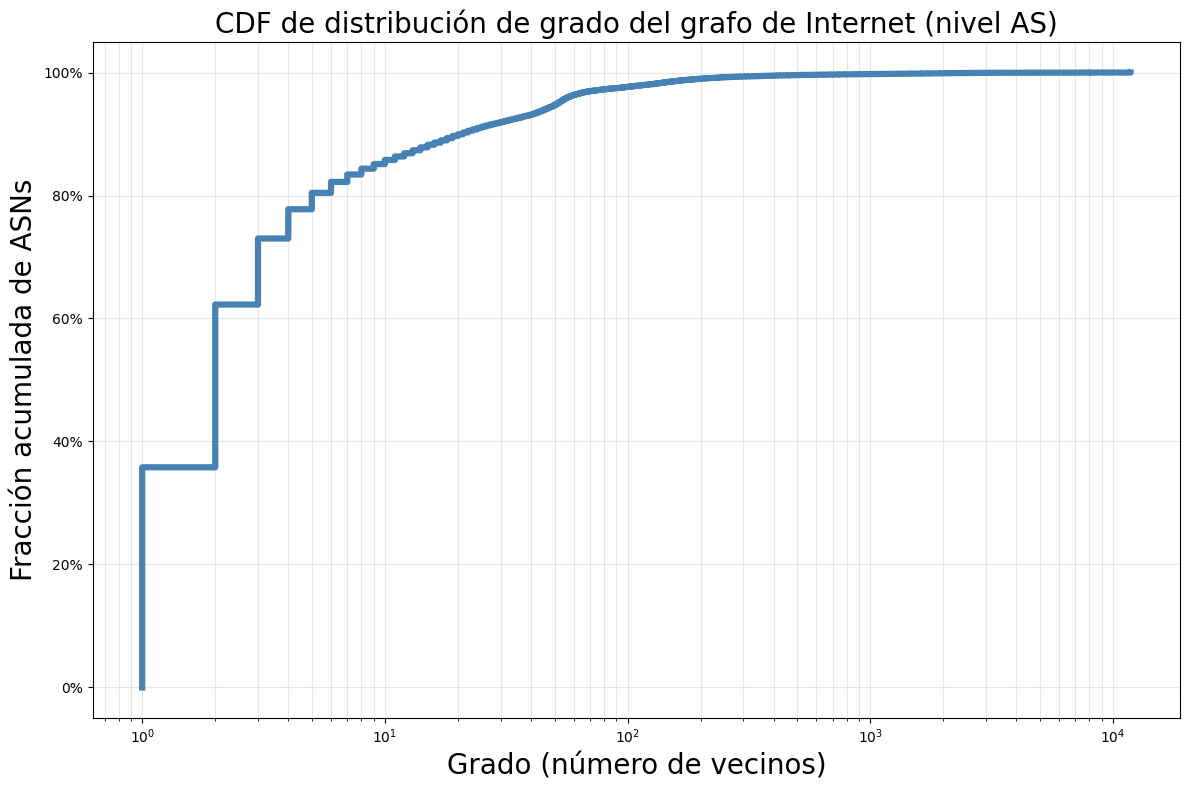

Nodos:          85,075
Grado mínimo:   1
Grado máximo:   11,821
Grado promedio: 16.6
Grado mediano:  2


In [13]:
import numpy as np
import matplotlib.pyplot as plt

degrees = np.array(sorted(d for _, d in G.degree()))
n = len(degrees)
ecdf_y = np.arange(1, n + 1) / n

fig, ax = plt.subplots(figsize=(12, 8))
ax.plot(degrees, ecdf_y, color="steelblue", linewidth=4.5, drawstyle="steps-post")
ax.set_xscale("log")
ax.set_title("CDF de distribución de grado del grafo de Internet (nivel AS)", fontsize=20)
ax.set_xlabel("Grado (número de vecinos)", fontsize=20)
ax.set_ylabel("Fracción acumulada de ASNs", fontsize=20)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

print(f"Nodos:          {n:,}")
print(f"Grado mínimo:   {degrees.min()}")
print(f"Grado máximo:   {degrees.max():,}")
print(f"Grado (promedio): {degrees.mean():.1f}")
print(f"Grado (mediana):  {int(np.median(degrees))}")

### ¿ Cuantos nodos tienen ordenes bajos ? 

In [20]:
degree_1_nodes = [node for node, deg in G.degree() if deg == 1]
cant_hojas     = len(list(degree_1_nodes))
pct_hojas      = (cant_hojas / n)*100
print(f"Hojas: {cant_hojas} / {pct_hojas}")

Hojas: 30456 / 35.79900088157508


In [22]:
degree_2_nodes = [node for node, deg in G.degree() if deg == 2]
cant_deg2      = len(list(degree_2_nodes))
pct_deg2       = (cant_deg2 / n)*100
print(f"Nodos de grado 2: {cant_deg2} / {pct_deg2}")

Nodos de grado 2: 22518 / 26.46841022627094


In [25]:
deg_menor_10   = [node for node, deg in G.degree() if deg <= 10]
cant_menor_10  = len(list(deg_menor_10))
print(f"Nodos con grados menor a 10: {cant_menor_10} / {(cant_menor_10/n)*100} % ")

Nodos con grados menor a 10: 72989 / 85.79371143109022 % 


# Muestreo de los caminos más cortos dentro del grafo

In [4]:
# Algunos shortest paths

nx.shortest_path(G, source='1797', target='3356')

['1797', '6057', '3356']

In [5]:
import random
import math
import statistics as stat

def random_sample_file(filename, k):
    with open(filename, 'r') as file:
        lines = file.readlines()
        # Ensure k is not larger than total lines
        sample_size = min(k, len(lines))
        return random.sample(lines, sample_size)

# Usage: get 10 random lines
sample = random_sample_file('../fetch/unique-asns-2025.txt', 10)
source = '1797'
lens = []
for s in sample:
    s = s.strip()
    target = s.lstrip('0')
    sp = nx.shortest_path(G, source=source, target=target)
    ln = len(sp)
    lens.append(ln)
    print(f"Shortest path from source={source} to={target} is {sp} with length {ln}")

#
print(f"Average length: {stat.mean(lens)}")
    
    


Shortest path from source=1797 to=28708 is ['1797', '6057', '5511', '28708'] with length 4
Shortest path from source=1797 to=395771 is ['1797', '6057', '15830', '22652', '395771'] with length 5
Shortest path from source=1797 to=3354 is ['1797', '6057', '3356', '6922', '3354'] with length 5
Shortest path from source=1797 to=209132 is ['1797', '6057', '44901', '209132'] with length 4
Shortest path from source=1797 to=42569 is ['1797', '6057', '12695', '42569'] with length 4
Shortest path from source=1797 to=144228 is ['1797', '27750', '11537', '23911', '38255', '144228'] with length 6
Shortest path from source=1797 to=41364 is ['1797', '6057', '3356', '41364'] with length 4
Shortest path from source=1797 to=329082 is ['1797', '6057', '174', '329082'] with length 4
Shortest path from source=1797 to=398820 is ['1797', '6057', '174', '701', '398820'] with length 5
Shortest path from source=1797 to=59507 is ['1797', '6057', '59507'] with length 3
Average length: 4.4


Average length: 2.34
Median length: 2.0
Maximum length seen: 6


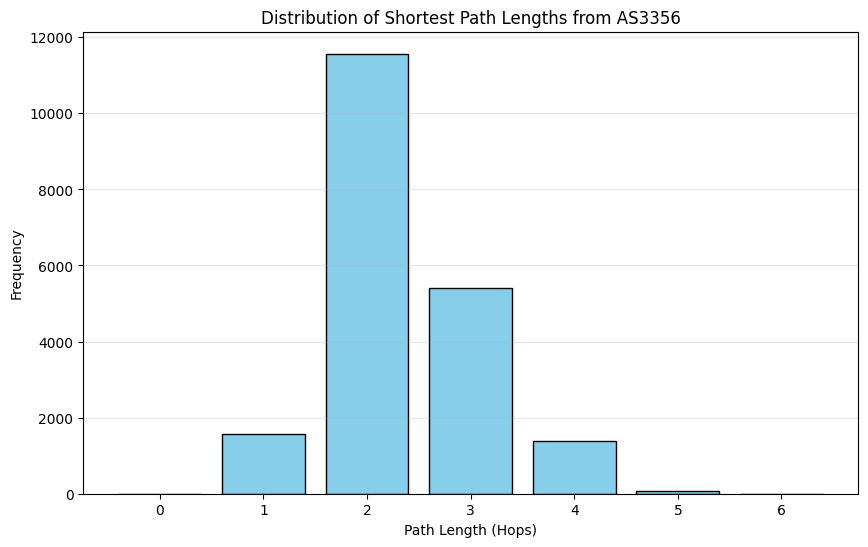

In [6]:
## Histograma

import random
import statistics as stat
import networkx as nx
import matplotlib.pyplot as plt
from collections import Counter

def get_random_sample(filename, k):
    """Memory-efficient way to sample lines from a large file."""
    with open(filename, 'r') as file:
        # Using list(file) is faster for medium files, 
        # but for massive files, consider reservoir sampling.
        lines = file.readlines()
        return random.sample(lines, min(k, len(lines)))

# Configuration
SOURCE_NODE = '3356'
SAMPLE_SIZE = 20000
FILE_PATH = '../fetch/unique-asns-2025.txt'

# 1. Get sample and calculate lengths
sample = get_random_sample(FILE_PATH, SAMPLE_SIZE)
path_lengths = []
max_length = 0

for line in sample:
    target = line.strip().lstrip('0')
    try:
        # nx.shortest_path_length is slightly faster than len(nx.shortest_path)
        length = nx.shortest_path_length(G, source=SOURCE_NODE, target=target)
        path_lengths.append(length)
        if length > max_length:
            max_length = length
    except nx.NetworkXNoPath:
        print(f"No path found for target: {target}")
    except nx.NodeNotFound:
        continue

# 2. Statistics
if path_lengths:
    print(f"Average length: {stat.mean(path_lengths):.2f}")
    print(f"Median length: {stat.median(path_lengths)}")
    print(f"Maximum length seen: {max_length}")

    # 3. Build the Histogram
    plt.figure(figsize=(10, 6))
    
    # Calculate bins based on the range of lengths
    bins = range(min(path_lengths), max(path_lengths) + 2)
    
    plt.hist(path_lengths, bins=bins, align='left', rwidth=0.8, color='skyblue', edgecolor='black')
    
    plt.title(f'Distribution of Shortest Path Lengths from AS{SOURCE_NODE}')
    plt.xlabel('Path Length (Hops)')
    plt.ylabel('Frequency')
    plt.xticks(bins[:-1])
    plt.grid(axis='y', alpha=0.3)
    
    plt.show()
else:
    print("No valid paths were found to sample.")

## Muestreando tanto origen como destino

In [7]:
# Also sample the origin

## Histograma

import random
import statistics as stat
import networkx as nx
import matplotlib.pyplot as plt
from collections import Counter

def get_random_sample(filename, k):
    """Memory-efficient way to sample lines from a large file."""
    with open(filename, 'r') as file:
        # Using list(file) is faster for medium files, 
        # but for massive files, consider reservoir sampling.
        lines = file.readlines()
        return random.sample(lines, min(k, len(lines)))

# Configuration
# SOURCE_NODE = '262159'
SAMPLE_SIZE = 300
FILE_PATH = ''../fetch/unique-asns-2025.txt'

# 1. Get sample and calculate lengths
sample_origin = get_random_sample(FILE_PATH, SAMPLE_SIZE)
sample = get_random_sample(FILE_PATH, SAMPLE_SIZE)
path_lengths = []
max_length = 0

for src in sample_origin:
    SOURCE_NODE = src.strip().lstrip('0')
    for line in sample:
        target = line.strip().lstrip('0')
        if SOURCE_NODE == target:
            continue
        try:
            # nx.shortest_path_length is slightly faster than len(nx.shortest_path)
            length = nx.shortest_path_length(G, source=SOURCE_NODE, target=target)
            path_lengths.append(length)
            if length > max_length:
                max_length = length
        except nx.NetworkXNoPath:
            print(f"No path found for target: {target}")
        except nx.NodeNotFound:
            continue

# 2. Statistics
if path_lengths:
    print(f"Average length: {stat.mean(path_lengths):.2f}")
    print(f"Median length: {stat.median(path_lengths)}")
    print(f"Maximum length seen: {max_length}")

    # 3. Build the Histogram
    plt.figure(figsize=(10, 6))
    
    # Calculate bins based on the range of lengths
    bins = range(min(path_lengths), max(path_lengths) + 2)
    
    plt.hist(path_lengths, bins=bins, align='left', rwidth=0.8, color='skyblue', edgecolor='black')
    
    plt.title(f'Distribution of Shortest Path Lengths from sampled origins and destinations')
    plt.xlabel('Path Length (Hops)')
    plt.ylabel('Frequency')
    plt.xticks(bins[:-1])
    plt.grid(axis='y', alpha=0.3)
    
    plt.show()
else:
    print("No valid paths were found to sample.")

SyntaxError: invalid decimal literal (589517865.py, line 22)

## Correr muchos experimentos

In [ ]:
# Also sample the origin

## Histograma

import random
import statistics as stat
import networkx as nx
import matplotlib.pyplot as plt
from collections import Counter

def get_random_sample(filename, k):
    """Memory-efficient way to sample lines from a large file."""
    with open(filename, 'r') as file:
        # Using list(file) is faster for medium files, 
        # but for massive files, consider reservoir sampling.
        lines = file.readlines()
        return random.sample(lines, min(k, len(lines)))

def sample_graph_distribution(N):
    # Configuration
    SAMPLE_SIZE = N
    FILE_PATH = '../fetch/asns-202504-week1.txt'
    
    # 1. Get sample and calculate lengths
    sample_origin = get_random_sample(FILE_PATH, SAMPLE_SIZE)
    sample = get_random_sample(FILE_PATH, SAMPLE_SIZE)
    path_lengths = []
    
    for src in sample_origin:
        SOURCE_NODE = src.strip().lstrip('0')
        for line in sample:
            target = line.strip().lstrip('0')
            if SOURCE_NODE == target:
                continue
            try:
                # nx.shortest_path_length is slightly faster than len(nx.shortest_path)
                length = nx.shortest_path_length(G, source=SOURCE_NODE, target=target)
                path_lengths.append(length)
            except nx.NetworkXNoPath:
                print(f"No path found for target: {target}")
            except nx.NodeNotFound:
                continue

    # 2. Statistics
    if path_lengths:
        avg_length = stat.mean(path_lengths)
        median = stat.median(path_lengths)
        stddev = stat.stdev(path_lengths)
        #print(f"Average length: {stat.mean(path_lengths):.2f}")
        #print(f"Median length: {stat.median(path_lengths)}")   

    return (avg_length, median, stddev)
## end sample graph distribution

## Run many experiments
avgs = []
stds = []
for x in range(10):
    (a,m,s) = sample_graph_distribution(100)
    avgs.append(a)
    stds.append(s)
    print(f"Run {x}: avg len {a}, stdev {s}")
##




## Plot the gaussian

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def plot_gaussian(mu, sigma):
    # Create a range of x values
    x = np.linspace(mu - 4*sigma, mu + 4*sigma, 1000)
    
    # Gaussian (normal distribution) formula
    y = (1 / (sigma * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x - mu) / sigma)**2)
    
    # Plot
    plt.figure()
    plt.plot(x, y)
    plt.title(f'Gaussian Distribution (mu={mu}, sigma={sigma})')
    plt.xlabel('x')
    plt.ylabel('Probability Density')
    plt.grid()
    plt.show()

# Example usage
plot_gaussian(mu=stat.mean(avgs), sigma=stat.mean(stds))
